## install the packages

In [22]:
! pip install scikit-learn streamlit pandas numpy matplotlib seaborn plotly

## import libraries

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import streamlit as st


## EDA (Explorality data analysis)

In [24]:
df = pd.read_csv('heart_2022_with_nans_.csv')
df.head()
df.shape

(445132, 40)

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 445132 entries, 0 to 445131
Data columns (total 40 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   State                      445132 non-null  object 
 1   Sex                        445132 non-null  object 
 2   GeneralHealth              443934 non-null  object 
 3   PhysicalHealthDays         434205 non-null  float64
 4   MentalHealthDays           436065 non-null  float64
 5   LastCheckupTime            436824 non-null  object 
 6   PhysicalActivities         444039 non-null  object 
 7   SleepHours                 439679 non-null  float64
 8   RemovedTeeth               433772 non-null  object 
 9   HadHeartAttack             442067 non-null  object 
 10  HadAngina                  440727 non-null  object 
 11  HadStroke                  443575 non-null  object 
 12  HadAsthma                  443359 non-null  object 
 13  HadSkinCancer              44

In [26]:
df.describe()

,PhysicalHealthDays,MentalHealthDays,SleepHours,HeightInMeters,WeightInKilograms,BMI
count,434205.000000,436065.000000,439679.000000,416480.000000,403054.000000,396326.000000
mean,4.347919,4.382649,7.022983,1.702691,83.074470,28.529842
std,8.688912,8.387475,1.502425,0.107177,21.448173,6.554889
min,0.000000,0.000000,1.000000,0.910000,22.680000,12.020000
25%,0.000000,0.000000,6.000000,1.630000,68.040000,24.130000
50%,0.000000,0.000000,7.000000,1.700000,80.740000,27.440000
75%,3.000000,5.000000,8.000000,1.780000,95.250000,31.750000
max,30.000000,30.000000,24.000000,2.410000,292.570000,99.640000


In [27]:
columns = ["Sex","GeneralHealth", "LastCheckupTime", "PhysicalActivities","SleepHours","HadHeartAttack","HadAngina","HadAsthma","HadCOPD","HadDepressiveDisorder","SmokerStatus","ECigaretteUsage","ChestScan","AgeCategory","BMI","AlcoholDrinkers","HIVTesting","TetanusLast10Tdap","HighRiskLastYear","CovidPos"]
df_new = df[columns].copy()

In [28]:
categorical_cols = df_new.select_dtypes(include="object").columns
 
for col in categorical_cols:
    print(df_new[col].value_counts(dropna=False))

Sex
Female    235893
Male      209239
Name: count, dtype: int64
GeneralHealth
Very good    148444
Good         143598
Excellent     71878
Fair          60273
Poor          19741
NaN            1198
Name: count, dtype: int64
LastCheckupTime
Within past year (anytime less than 12 months ago)         350944
Within past 2 years (1 year but less than 2 years ago)      41919
Within past 5 years (2 years but less than 5 years ago)     24882
5 or more years ago                                         19079
NaN                                                          8308
Name: count, dtype: int64
PhysicalActivities
Yes    337559
No     106480
NaN      1093
Name: count, dtype: int64
HadHeartAttack
No     416959
Yes     25108
NaN      3065
Name: count, dtype: int64
HadAngina
No     414176
Yes     26551
NaN      4405
Name: count, dtype: int64
HadAsthma
No     376665
Yes     66694
NaN      1773
Name: count, dtype: int64
HadCOPD
No     407257
Yes     35656
NaN      2219
Name: count, dtype: int64
Ha

In [29]:
for col in ["BMI", "SleepHours"]:
    Q1 = df_new[col].quantile(0.25)
    Q3 = df_new[col].quantile(0.75)
 
    IQR = Q3 - Q1
 
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
 
    outliers = df_new[
        (df_new[col] < lower) |
        (df_new[col] > upper)
    ]
 
    print(f"\n{col}")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Number of outliers:", len(outliers))


BMI
Lower bound: 12.7
Upper bound: 43.18
Number of outliers: 12339

SleepHours
Lower bound: 3.0
Upper bound: 11.0
Number of outliers: 7260


In [30]:
print(df_new["SleepHours"].value_counts().sort_index())

SleepHours
1.0       1154
2.0       1549
3.0       3260
4.0      12433
5.0      30122
6.0      95880
7.0     132927
8.0     125442
9.0      21210
10.0     10459
11.0       686
12.0      3004
13.0       165
14.0       295
15.0       317
16.0       329
17.0        27
18.0       168
19.0        16
20.0       143
21.0         4
22.0        19
23.0        18
24.0        52
Name: count, dtype: int64


## Handling Missing value - clean Data

In [113]:
#count duplicated columns based on their values
df_new.duplicated().sum()

#validate duplicate removal
print("Duplicated rows:", df_new.duplicated().sum())

Duplicated rows: 15399


In [31]:
df_new.isna().sum()

Sex                          0
GeneralHealth             1198
LastCheckupTime           8308
PhysicalActivities        1093
SleepHours                5453
HadHeartAttack            3065
HadAngina                 4405
HadAsthma                 1773
HadCOPD                   2219
HadDepressiveDisorder     2812
SmokerStatus             35462
ECigaretteUsage          35660
ChestScan                56046
AgeCategory               9079
BMI                      48806
AlcoholDrinkers          46574
HIVTesting               66127
TetanusLast10Tdap        82516
HighRiskLastYear         50623
CovidPos                 50764
dtype: int64

In [32]:
df_new = df_new.dropna(subset=["HadHeartAttack"]).copy()

In [33]:
columns = ["GeneralHealth", "LastCheckupTime", "PhysicalActivities","HadAngina","HadAsthma","HadCOPD","HadDepressiveDisorder","SmokerStatus","ECigaretteUsage","ChestScan","AgeCategory","AlcoholDrinkers","HIVTesting","TetanusLast10Tdap","HighRiskLastYear","CovidPos"]
df_new[columns] = df_new[columns].fillna("unknown")

In [34]:
print(df_new.isna().sum())

Sex                          0
GeneralHealth                0
LastCheckupTime              0
PhysicalActivities           0
SleepHours                5196
HadHeartAttack               0
HadAngina                    0
HadAsthma                    0
HadCOPD                      0
HadDepressiveDisorder        0
SmokerStatus                 0
ECigaretteUsage              0
ChestScan                    0
AgeCategory                  0
BMI                      48110
AlcoholDrinkers              0
HIVTesting                   0
TetanusLast10Tdap            0
HighRiskLastYear             0
CovidPos                     0
dtype: int64


<Axes: xlabel='Sex', ylabel='count'>

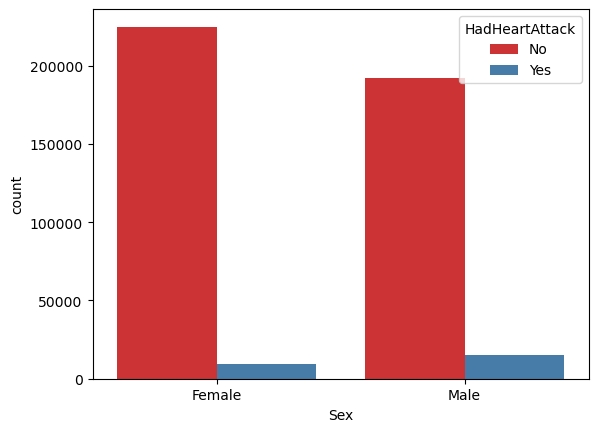

In [35]:
sns.countplot(x='Sex',hue='HadHeartAttack',data=df_new, palette='Set1')

In [36]:
px.histogram(df_new, x='AgeCategory', color='HadHeartAttack',marginal='box', nbins=30, title='Heart Attack by Age Category')

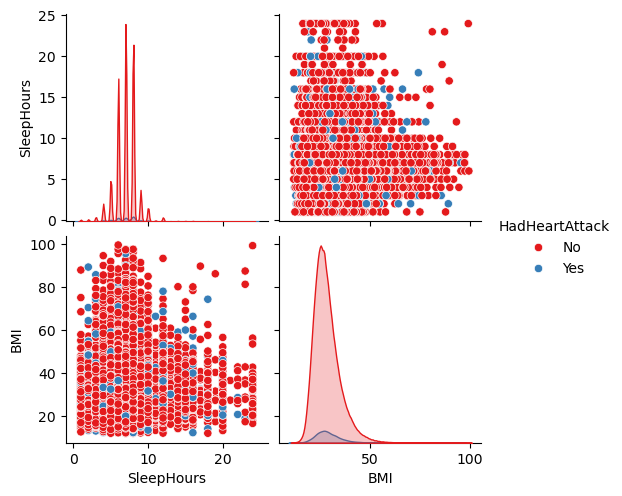

In [37]:
sns.pairplot(df_new, hue="HadHeartAttack",  palette="Set1")

## split input and output

In [116]:
x = df_new.drop('HadHeartAttack', axis=1)
y = df_new['HadHeartAttack']

## split data into train and test

In [39]:
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.2, random_state=42, stratify=y)

In [40]:
numeric_columns = ["SleepHours", "BMI"]
medians = x_train[numeric_columns].median()

x_train[numeric_columns] = x_train[numeric_columns].fillna(medians)
x_test[numeric_columns] = x_test[numeric_columns].fillna(medians)

# Check missing values after filling
print(x_train.isna().sum())
print(x_test.isna().sum())

Sex                      0
GeneralHealth            0
LastCheckupTime          0
PhysicalActivities       0
SleepHours               0
HadAngina                0
HadAsthma                0
HadCOPD                  0
HadDepressiveDisorder    0
SmokerStatus             0
ECigaretteUsage          0
ChestScan                0
AgeCategory              0
BMI                      0
AlcoholDrinkers          0
HIVTesting               0
TetanusLast10Tdap        0
HighRiskLastYear         0
CovidPos                 0
dtype: int64
Sex                      0
GeneralHealth            0
LastCheckupTime          0
PhysicalActivities       0
SleepHours               0
HadAngina                0
HadAsthma                0
HadCOPD                  0
HadDepressiveDisorder    0
SmokerStatus             0
ECigaretteUsage          0
ChestScan                0
AgeCategory              0
BMI                      0
AlcoholDrinkers          0
HIVTesting               0
TetanusLast10Tdap        0
HighRiskLastYea

## apply scaling

In [41]:
# Convert text categories into numeric columns
x_train = pd.get_dummies(x_train)
x_test = pd.get_dummies(x_test)

# Ensure test columns match training columns
x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

## Apply Modeling

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
lr = LogisticRegression(random_state=42)
lr.fit(x_train_scaled, y_train)
y_pred = lr.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, lr.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))



classification report training:
               precision    recall  f1-score   support

          No       0.96      0.99      0.97    333567
         Yes       0.55      0.25      0.35     20086

    accuracy                           0.95    353653
   macro avg       0.76      0.62      0.66    353653
weighted avg       0.93      0.95      0.94    353653

classification report testing:
               precision    recall  f1-score   support

          No       0.96      0.99      0.97     83392
         Yes       0.55      0.25      0.35      5022

    accuracy                           0.95     88414
   macro avg       0.75      0.62      0.66     88414
weighted avg       0.93      0.95      0.94     88414



In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
y_pred = knn.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, knn.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

'from sklearn.neighbors import KNeighborsClassifier\nknn = KNeighborsClassifier(n_neighbors=5)\nknn.fit(x_train_scaled, y_train)\ny_pred = knn.predict(x_test_scaled)\nprint("classification report training:\n", classification_report(y_train, knn.predict(x_train_scaled)))\nprint("classification report testing:\n", classification_report(y_test, y_pred))'

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42 , max_depth=5)
dt.fit(x_train_scaled, y_train)
y_pred = dt.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, dt.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

'from sklearn.tree import DecisionTreeClassifier\ndt = DecisionTreeClassifier(random_state=42 , max_depth=5)\ndt.fit(x_train_scaled, y_train)\ny_pred = dt.predict(x_test_scaled)\nprint("classification report training:\n", classification_report(y_train, dt.predict(x_train_scaled)))\nprint("classification report testing:\n", classification_report(y_test, y_pred))'

In [45]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42 , n_estimators=100, max_depth=5)
rf.fit(x_train_scaled, y_train)
y_pred = rf.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, rf.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))



c:\Users\salam\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\Users\salam\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\Users\salam\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



classification report training:
               precision    recall  f1-score   support

          No       0.94      1.00      0.97    333567
         Yes       0.00      0.00      0.00     20086

    accuracy                           0.94    353653
   macro avg       0.47      0.50      0.49    353653
weighted avg       0.89      0.94      0.92    353653



c:\Users\salam\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\Users\salam\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



classification report testing:
               precision    recall  f1-score   support

          No       0.94      1.00      0.97     83392
         Yes       0.00      0.00      0.00      5022

    accuracy                           0.94     88414
   macro avg       0.47      0.50      0.49     88414
weighted avg       0.89      0.94      0.92     88414



c:\Users\salam\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



## cross validation

In [46]:
from sklearn.model_selection import KFold , cross_validate 
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_validate(lr, x_train_scaled, y_train, cv=kfold, return_train_score=True)
scores 


{'fit_time': array([2.84994864, 2.53476715, 2.17066073, 2.49832129, 2.14372897,
        2.43125653, 2.31996131, 2.25105953, 2.21841359, 2.19273949]),
 'score_time': array([0.14268708, 0.0986414 , 0.09555817, 0.12931347, 0.08676243,
        0.09248567, 0.09438014, 0.09603238, 0.09487653, 0.09865046]),
 'test_score': array([0.9448623 , 0.94474919, 0.94737884, 0.9474339 , 0.94573731,
        0.94618974, 0.94449314, 0.94650078, 0.94686837, 0.94548282]),
 'train_score': array([0.94608954, 0.94616808, 0.94586961, 0.94585721, 0.946074  ,
        0.94597032, 0.94621538, 0.94592319, 0.9458415 , 0.9460897 ])}

## hyper parameter tuning

In [47]:
'''from sklearn.model_selection import GridSearchCV
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    'class_weight': [None,'balanced',{'No': 1, 'Yes': 2},{'No': 1, 'Yes': 3},{'No': 1, 'Yes': 5}
    ]
}
grid_search = GridSearchCV(
    LogisticRegression(random_state=42, max_iter=1000), param_grid, cv=5, scoring="accuracy"
)
grid_search.fit(x_train_scaled, y_train)'''


'from sklearn.model_selection import GridSearchCV\nparam_grid = {\n    "C": [0.01, 0.1, 1, 10, 100],\n    \'class_weight\': [None,\'balanced\',{\'No\': 1, \'Yes\': 2},{\'No\': 1, \'Yes\': 3},{\'No\': 1, \'Yes\': 5}\n    ]\n}\ngrid_search = GridSearchCV(\n    LogisticRegression(random_state=42, max_iter=1000), param_grid, cv=5, scoring="accuracy"\n)\ngrid_search.fit(x_train_scaled, y_train)'

In [48]:
from sklearn.metrics import make_scorer, f1_score
 
f1_yes = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

In [49]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'C': [0.001,0.01, 0.05, 0.5, 2, 5, 20],
    'class_weight': [
        None,
        'balanced',
        {'No': 1, 'Yes': 2},
        {'No': 1, 'Yes': 3},
        {'No': 1, 'Yes': 5}
    ]
}
grid_search = GridSearchCV(
    LogisticRegression(random_state=42, max_iter=1000),
    param_grid,
    cv=5,
    scoring= f1_yes
)
 
# Run hyperparameter tuning
grid_search.fit(x_train_scaled, y_train)
 
# Display results
grid_search

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000, random_state=42),
             param_grid={'C': [0.001, 0.01, 0.05, 0.5, 2, 5, 20],
                         'class_weight': [None, 'balanced', {'No': 1, 'Yes': 2},
                                          {'No': 1, 'Yes': 3},
                                          {'No': 1, 'Yes': 5}]},
             scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes, zero_division=0))

In [ ]:
print("Best Parameters:", grid_search.best_params_)
print("Best F1-score:", grid_search.best_score_)

In [51]:
lr = LogisticRegression(C=0.001, class_weight={'No': 1, 'Yes': 3}, random_state=42, max_iter=1000)
lr.fit(x_train_scaled, y_train)

y_pred = lr.predict(x_test_scaled)

print("classification report training:\n", classification_report(y_train, lr.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

          No       0.97      0.97      0.97    333567
         Yes       0.47      0.48      0.47     20086

    accuracy                           0.94    353653
   macro avg       0.72      0.72      0.72    353653
weighted avg       0.94      0.94      0.94    353653

classification report testing:
               precision    recall  f1-score   support

          No       0.97      0.97      0.97     83392
         Yes       0.46      0.48      0.47      5022

    accuracy                           0.94     88414
   macro avg       0.72      0.72      0.72     88414
weighted avg       0.94      0.94      0.94     88414



## create the pipline for deployemnt

In [52]:
df


,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,...,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Alabama,Female,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,No,8.0,NaN,No,...,NaN,NaN,NaN,No,No,Yes,No,"Yes, received tetanus shot but not sure what type",No,No
1,Alabama,Female,Excellent,0.0,0.0,NaN,No,6.0,NaN,No,...,1.60,68.04,26.57,No,No,No,No,"No, did not receive any tetanus shot in the pa...",No,No
2,Alabama,Female,Very good,2.0,3.0,Within past year (anytime less than 12 months ...,Yes,5.0,NaN,No,...,1.57,63.50,25.61,No,No,No,No,NaN,No,Yes
3,Alabama,Female,Excellent,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,7.0,NaN,No,...,1.65,63.50,23.30,No,No,Yes,Yes,"No, did not receive any tetanus shot in the pa...",No,No
4,Alabama,Female,Fair,2.0,0.0,Within past year (anytime less than 12 months ...,Yes,9.0,NaN,No,...,1.57,53.98,21.77,Yes,No,No,Yes,"No, did not receive any tetanus shot in the pa...",No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445127,Virgin Islands,Female,Good,0.0,3.0,Within past 2 years (1 year but less than 2 ye...,Yes,6.0,None of them,No,...,1.65,69.85,25.63,NaN,Yes,No,No,"No, did not receive any tetanus shot in the pa...",No,Yes
445128,Virgin Islands,Female,Excellent,2.0,2.0,Within past year (anytime less than 12 months ...,Yes,7.0,None of them,No,...,1.70,83.01,28.66,No,Yes,Yes,No,"Yes, received tetanus shot but not sure what type",No,No
445129,Virgin Islands,Female,Poor,30.0,30.0,5 or more years ago,No,5.0,1 to 5,No,...,1.70,49.90,17.23,NaN,No,No,No,"No, did not receive any tetanus shot in the pa...",No,No
445130,Virgin Islands,Male,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,No,5.0,None of them,Yes,...,1.83,108.86,32.55,No,Yes,Yes,Yes,"No, did not receive any tetanus shot in the pa...",No,Yes


In [53]:
df.isna().sum()

State                            0
Sex                              0
GeneralHealth                 1198
PhysicalHealthDays           10927
MentalHealthDays              9067
LastCheckupTime               8308
PhysicalActivities            1093
SleepHours                    5453
RemovedTeeth                 11360
HadHeartAttack                3065
HadAngina                     4405
HadStroke                     1557
HadAsthma                     1773
HadSkinCancer                 3143
HadCOPD                       2219
HadDepressiveDisorder         2812
HadKidneyDisease              1926
HadArthritis                  2633
HadDiabetes                   1087
DeafOrHardOfHearing          20647
BlindOrVisionDifficulty      21564
DifficultyConcentrating      24240
DifficultyWalking            24012
DifficultyDressingBathing    23915
DifficultyErrands            25656
SmokerStatus                 35462
ECigaretteUsage              35660
ChestScan                    56046
RaceEthnicityCategor

## split input and output

In [115]:
# Remove records with missing target values
df_new = df_new.dropna(subset=['HadHeartAttack'])

#remove duplicate records
df_new = df_new.drop_duplicates()

In [81]:
x = df_new.drop('HadHeartAttack', axis=1)
y = df_new['HadHeartAttack']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.2, random_state=42, stratify=y)

In [83]:
print("Missing target values:", df_new['HadHeartAttack'].isnull().sum())
print("Missing training labels:", y_train.isnull().sum())
print("Missing testing labels:", y_test.isnull().sum())

Missing target values: 0
Missing training labels: 0
Missing testing labels: 0


In [84]:
numerical_columns = x_train.select_dtypes(include=['int64', 'float64']).columns
numerical_columns

Index(['SleepHours', 'BMI'], dtype='object')

In [85]:
cat_columns = x_train.select_dtypes(include=['object','category']).columns
cat_columns

Index(['Sex', 'GeneralHealth', 'LastCheckupTime', 'PhysicalActivities',
       'HadAngina', 'HadAsthma', 'HadCOPD', 'HadDepressiveDisorder',
       'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'AgeCategory',
       'AlcoholDrinkers', 'HIVTesting', 'TetanusLast10Tdap',
       'HighRiskLastYear', 'CovidPos'],
      dtype='object')

In [86]:
x_train['GeneralHealth'].unique()

array(['Poor', 'Excellent', 'Very good', 'Good', 'Fair', 'unknown'],
      dtype=object)

In [87]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False))
])
numerical_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler(with_mean=False))])

In [88]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(drop='first'))
])
cat_pipeline

Pipeline(steps=[('imputer',
                 SimpleImputer(fill_value='Unknown', strategy='constant')),
                ('encoder', OneHotEncoder(drop='first'))])

In [89]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', cat_pipeline, cat_columns)
], remainder='passthrough')

In [90]:
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  StandardScaler(with_mean=False))]),
                                 Index(['SleepHours', 'BMI'], dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='Unknown',
                                                                strategy='constant')),
                                                 ('encoder',
                                                  OneHotEncoder(drop='first'))]),
                                 Index(['Sex', 'GeneralHealth', 'LastCheckupTime', 'PhysicalActivities',
       'HadAngina', 'HadAsthma', 'HadCOPD', 'HadDepressiveDisorder',
       'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'AgeCategory',
       'AlcoholDrinkers', 'HIVTesting', 'TetanusLast10Tdap',
       'HighRiskLastYear', 'CovidPos'],
      dtype='object'))])

In [91]:
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(C=0.001, class_weight={'No': 1, 'Yes': 3}, random_state=42, max_iter=1000))
])
final_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  Index(['SleepHours', 'BMI'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   One...
                                                  Index(['Sex', 'GeneralHealth', 'LastCheckupTime', 'PhysicalActivities',
       'HadAngina', 'HadAsthma', 'HadCOPD', 'HadDepressiveDisorder',
       'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'AgeCategory',
       'AlcoholDrinkers', 'HIVTesting', 'TetanusLast10Tdap',
       'HighRiskLastYear', 'CovidPos'],
      dtype='object'))])),
                ('model',
                 LogisticRegression(C=0.001, class_weight={'No': 1, 'Yes': 3},
                                    max_iter=1000, random_state=42))])

In [92]:
final_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  Index(['SleepHours', 'BMI'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   One...
                                                  Index(['Sex', 'GeneralHealth', 'LastCheckupTime', 'PhysicalActivities',
       'HadAngina', 'HadAsthma', 'HadCOPD', 'HadDepressiveDisorder',
       'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'AgeCategory',
       'AlcoholDrinkers', 'HIVTesting', 'TetanusLast10Tdap',
       'HighRiskLastYear', 'CovidPos'],
      dtype='object'))])),
                ('model',
                 LogisticRegression(C=0.001, class_weight={'No': 1, 'Yes': 3},
                                    max_iter=1000, random_state=42))])

In [94]:
y_pred = final_pipeline.predict(x_test)
y_pred

array(['No', 'No', 'No', ..., 'No', 'No', 'No'], dtype=object)

In [96]:
import joblib
joblib.dump(final_pipeline, 'heart_attack_model.pkl')

['heart_attack_model.pkl']

In [109]:
classifier = joblib.load('heart_attack_model.pkl')

In [110]:
classifier.predict(pd.DataFrame({
    'SleepHours': [7],
    'BMI': [25],
    'Sex': ['Female'],
    'GeneralHealth': ['Good'],
    'LastCheckupTime': ['Within past year (anytime less than 12 months ago)'],
    'PhysicalActivities': ['Yes'],
    'HadAngina': ['No'],
    'HadAsthma': ['No'],
    'HadCOPD': ['No'],
    'HadDepressiveDisorder': ['No'],
    'SmokerStatus': ['Never smoked'],
    'ECigaretteUsage': ['Never used e-cigarettes in my entire life'],
    'ChestScan': ['No'],
    'AgeCategory': ['Age 55 to 59'],
    'AlcoholDrinkers': ['No'],
    'HIVTesting': ['Yes'],
    'TetanusLast10Tdap': ['Yes, received Tdap'],
    'HighRiskLastYear': ['No'],
    'CovidPos': ['No']
}))

array(['No'], dtype=object)

In [ ]:
%%writefile app.py
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

MODEL_PATH = Path(__file__).resolve().parent / "heart_attack_model.pkl"


@st.cache_resource
def load_model(path, modified_time):
    # The modification time refreshes the cache after the model is replaced.
    return joblib.load(path)


GROUPS = [
    ("01", "About you", "Start with your everyday profile.", [
        ("Sex", "Sex"), ("AgeCategory", "Age group"),
        ("BMI", "Body mass index (BMI)"), ("SleepHours", "Sleep per night (hours)"),
        ("GeneralHealth", "General health")]),
    ("02", "Everyday habits", "Choose the answers that best describe you.", [
        ("PhysicalActivities", "Physical activities"), ("SmokerStatus", "Smoking status"),
        ("ECigaretteUsage", "E-cigarette use"), ("AlcoholDrinkers", "Alcohol consumption")]),
    ("03", "Health history", "Select your reported history for each question.", [
        ("HadAngina", "History of angina"), ("HadAsthma", "History of asthma"),
        ("HadCOPD", "History of COPD"),
        ("HadDepressiveDisorder", "History of depressive disorder"),
        ("CovidPos", "Positive COVID-19 test")]),
    ("04", "Checkups & screening", "A few final details from the survey.", [
        ("LastCheckupTime", "Last routine checkup"), ("ChestScan", "Chest scan"),
        ("HIVTesting", "HIV testing"), ("TetanusLast10Tdap", "Tetanus shot in the past 10 years"),
        ("HighRiskLastYear", "High-risk activity in the past year (survey field)")]),
]


def reset_answers():
    for key in list(st.session_state):
        if key.startswith("answer_") or key == "prediction_result":
            del st.session_state[key]


def predict_heart_attack(model, input_data):
    frame = pd.DataFrame(input_data).reindex(columns=model.feature_names_in_)
    return str(model.predict(frame)[0])


def main():
    st.set_page_config(page_title="Heartwise | Heart history explorer", page_icon="?", layout="wide")
    st.markdown("""
    <style>
    .stApp {background: #f5f8fa; color: #183641;}
    .block-container {max-width: 1120px; padding-top: 2rem; padding-bottom: 3rem;}
    .hero {background: linear-gradient(120deg, #103c48, #126b70); border-radius: 24px;
           padding: 38px; color: white; margin: 12px 0 26px;}
    .hero h1 {color: white; font-size: clamp(2rem, 5vw, 3.3rem); letter-spacing: -1.5px;}
    .hero p {color: #d7efec; max-width: 640px; font-size: 1.05rem;}
    .eyebrow {text-transform: uppercase; letter-spacing: 2px; font-size: .75rem; font-weight: 700;}
    .badge {display: inline-block; background: #f9b9a5; color: #263c43; padding: 6px 14px;
            border-radius: 30px; font-size: .8rem; font-weight: 600; margin-top: 8px;}
    .step {font-size: .78rem; font-weight: 700; color: #087f80; letter-spacing: 1px;}
    [data-testid="stVerticalBlockBorderWrapper"] {border-radius: 18px;}
    [data-testid="stForm"] {background: white; border-radius: 20px;}
    div[data-testid="stFormSubmitButton"] button {background: #107a7b; color: white;
        border: none; border-radius: 12px; padding: .7rem 1.5rem; font-weight: 600;}
    div[data-testid="stFormSubmitButton"] button:hover {background: #095f60; color: white;}
    </style>
    """, unsafe_allow_html=True)
    st.markdown("**? HEARTWISE** ? A machine learning explorer")
    st.markdown("""
    <section class="hero">
      <div class="eyebrow">Your answers. A model's perspective.</div>
      <h1>A clearer view of<br>your heart history.</h1>
      <p>Explore how a trained model classifies reported heart attack history
      using lifestyle and health survey answers.</p>
      <span class="badge">19 questions &nbsp; ? &nbsp; 4 simple sections</span>
    </section>
    """, unsafe_allow_html=True)

    try:
        model = load_model(str(MODEL_PATH), MODEL_PATH.stat().st_mtime_ns)
    except (OSError, ValueError, ImportError):
        st.error("The prediction model could not be loaded. Check the model file and installed dependencies.")
        st.stop()

    preprocessor = model.named_steps["preprocessor"]
    encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
    cat_columns = next(columns for name, _, columns in preprocessor.transformers_ if name == "cat")
    choices = {column: list(values) for column, values in zip(cat_columns, encoder.categories_)}

    with st.expander("How to read your result"):
        st.write("The model returns Yes or No for a reported history of heart attack. "
                 "It can make mistakes. It does not predict a future event or diagnose a current one.")
        st.write("Review every answer before submitting. The starting values are examples, not a personal profile.")

    left, right = st.columns([3, 1])
    with left:
        st.subheader("Build your profile")
        st.caption("Review all four sections, then select Predict.")
    with right:
        st.button("Reset answers", on_click=reset_answers, use_container_width=True)

    input_data = {}
    with st.form("heart_profile"):
        for number, title, description, fields in GROUPS:
            st.markdown(f'<div class="step">SECTION {number}</div>', unsafe_allow_html=True)
            st.subheader(title)
            st.caption(description)
            columns = st.columns(2)
            for index, (field, label) in enumerate(fields):
                with columns[index % 2]:
                    if field == "BMI":
                        value = st.number_input(label, min_value=1.0, max_value=150.0,
                                                value=25.0, step=0.1, key="answer_" + field)
                    elif field == "SleepHours":
                        value = st.number_input(label, min_value=0, max_value=24,
                                                value=7, key="answer_" + field)
                    else:
                        options = choices[field]
                        defaults = {"Sex": "Female", "AgeCategory": "Age 55 to 59",
                                    "GeneralHealth": "Good", "SmokerStatus": "Never smoked",
                                    "ECigaretteUsage": "Never used e-cigarettes in my entire life",
                                    "LastCheckupTime": "Within past year (anytime less than 12 months ago)"}
                        default = defaults.get(field, "No")
                        selected = options.index(default) if default in options else 0
                        value = st.selectbox(label, options, index=selected, key="answer_" + field)
                    input_data[field] = [value]
            st.divider()
        submitted = st.form_submit_button("Predict", use_container_width=True)

    if submitted:
        st.session_state.pop("prediction_result", None)
        try:
            result = predict_heart_attack(model, input_data)
            st.session_state["prediction_result"] = (result, input_data)
        except (ValueError, KeyError):
            st.error("These answers could not be processed. Check that the saved model matches this app.")

    if "prediction_result" in st.session_state:
        result, submitted_data = st.session_state["prediction_result"]
        with st.container(border=True):
            st.subheader("Your model result")
            st.caption("Based on your last submitted answers. Submit again after making changes.")
            if result == "Yes":
                st.warning("The model predicts a history of heart attack.")
            else:
                st.info("The model predicts no history of heart attack.")
            with st.expander("Review submitted answers"):
                st.dataframe(pd.DataFrame({"Question": [label for _, _, _, fields in GROUPS for _, label in fields],
                                          "Answer": [str(submitted_data[field][0]) for _, _, _, fields in GROUPS for field, _ in fields]}),
                             hide_index=True, use_container_width=True)
    else:
        st.info("Your result will appear here after you submit your profile.")
    st.caption("This prediction is not a medical diagnosis and does not determine whether you are currently having a heart attack.")
    st.markdown("---")
    st.caption("HEARTWISE ? Built for learning and exploration")


if __name__ == "__main__":
    main()
